
Dataset Description:
How many features?  11
Classification or regression problem? Classification (binary: on time or not)
How many data points?  10999
Features types: Quantitative (e.g., Cost_of_the_Product, Weight_in_gms), Categorical (e.g., Warehouse_block, Gender)
Categorical features need encoding: Yes, for ML models.


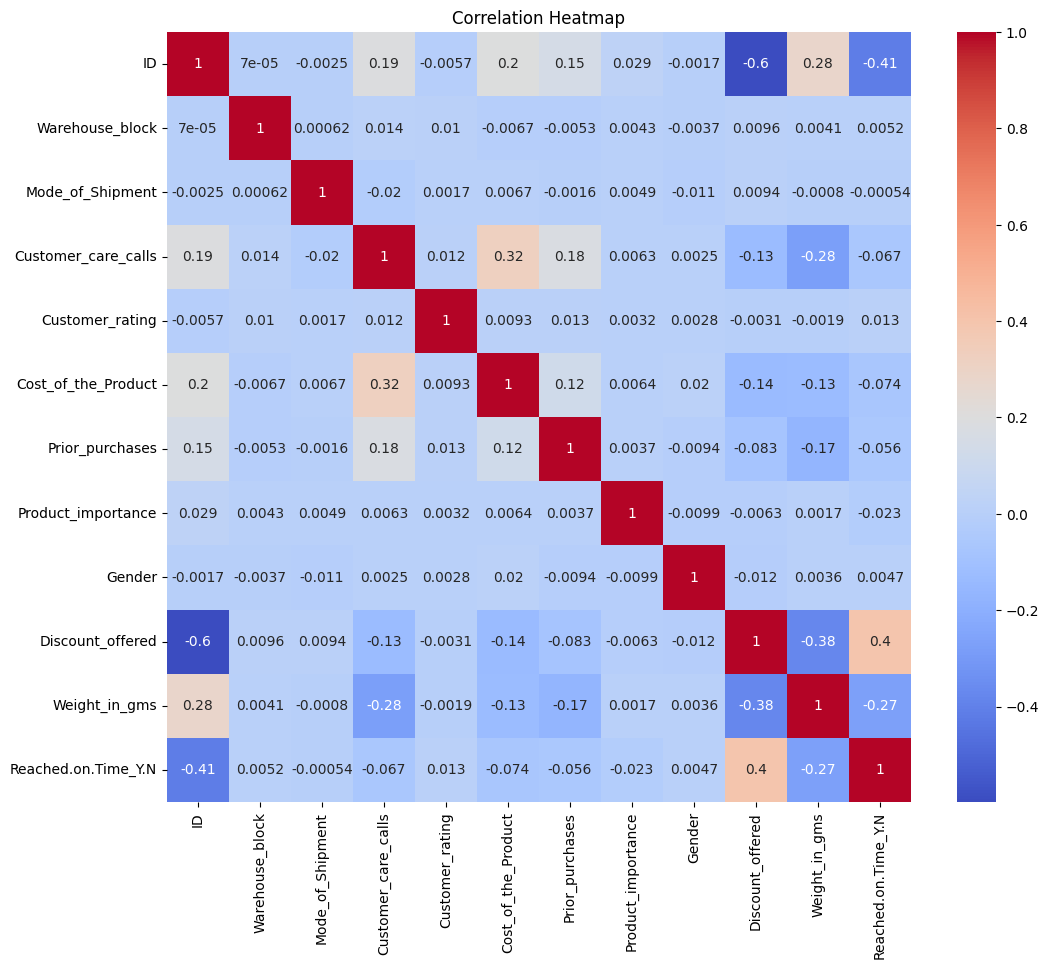

After correlation: Discount_offered and Reached.on.Time_Y.N have moderate correlation. Weight_in_gms negative correlation with target.


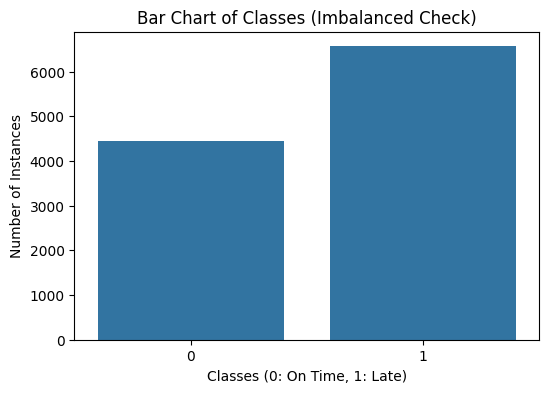

Imbalanced? Yes, more late shipments (1) than on time (0).

EDA:
   ID Warehouse_block Mode_of_Shipment  Customer_care_calls  Customer_rating  \
0   1               D           Flight                    4                2   
1   2               F           Flight                    4                5   
2   3               A           Flight                    2                2   
3   4               B           Flight                    3                3   
4   5               C           Flight                    2                2   

   Cost_of_the_Product  Prior_purchases Product_importance Gender  \
0                  177                3                low      F   
1                  216                2                low      M   
2                  183                4                low      M   
3                  176                4             medium      M   
4                  184                3             medium      F   

   Discount_offered  Weight_in_gms  Rea

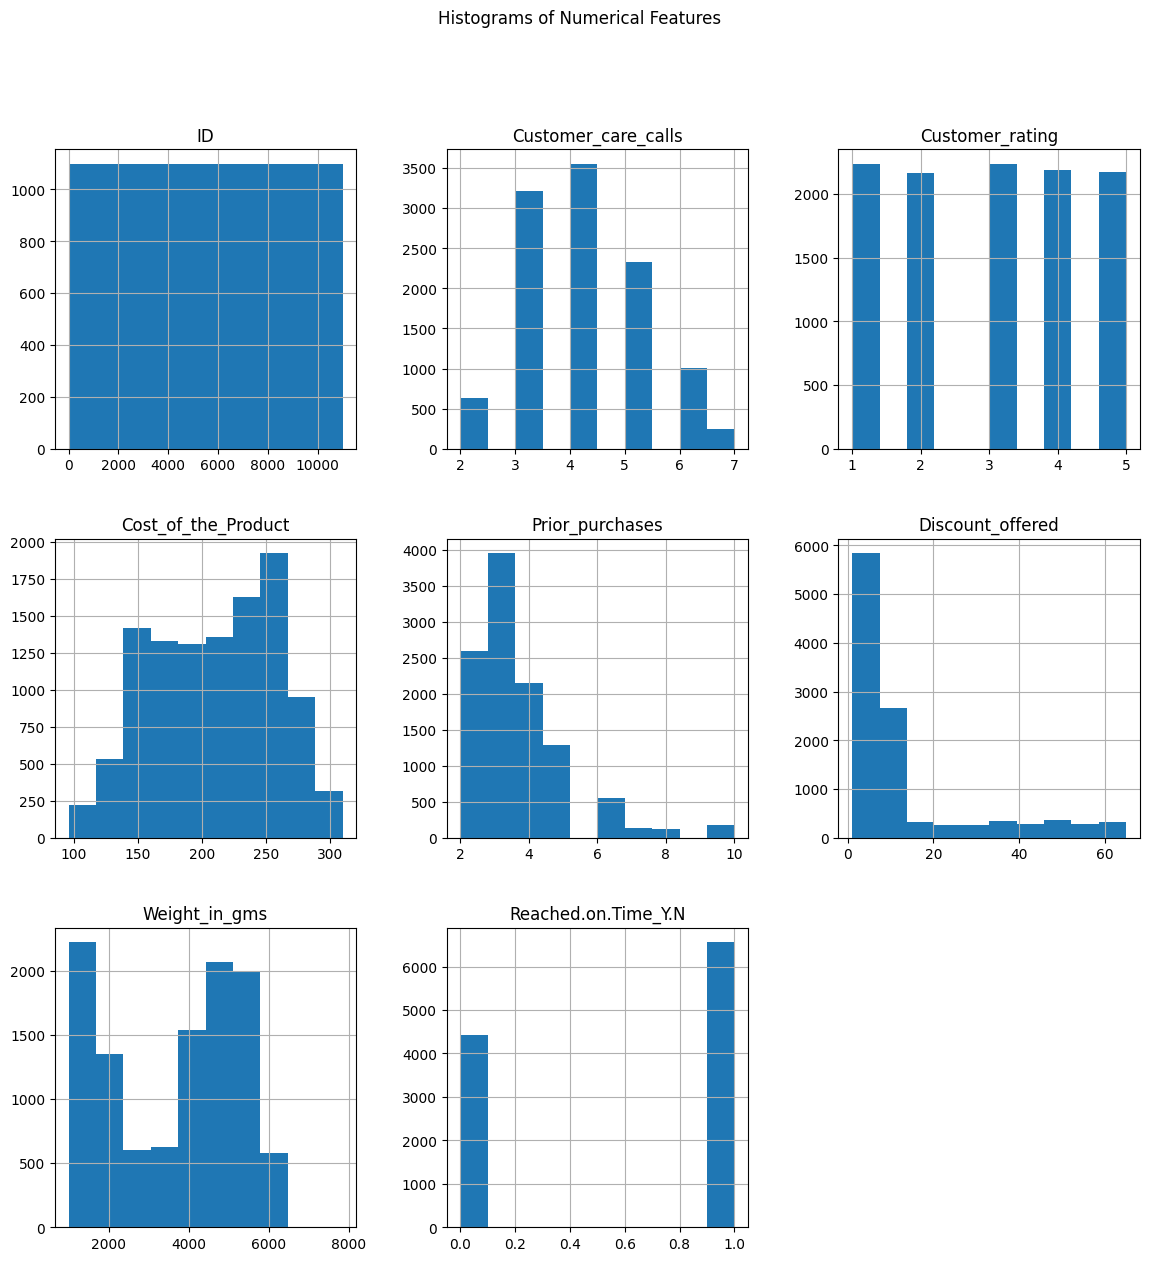

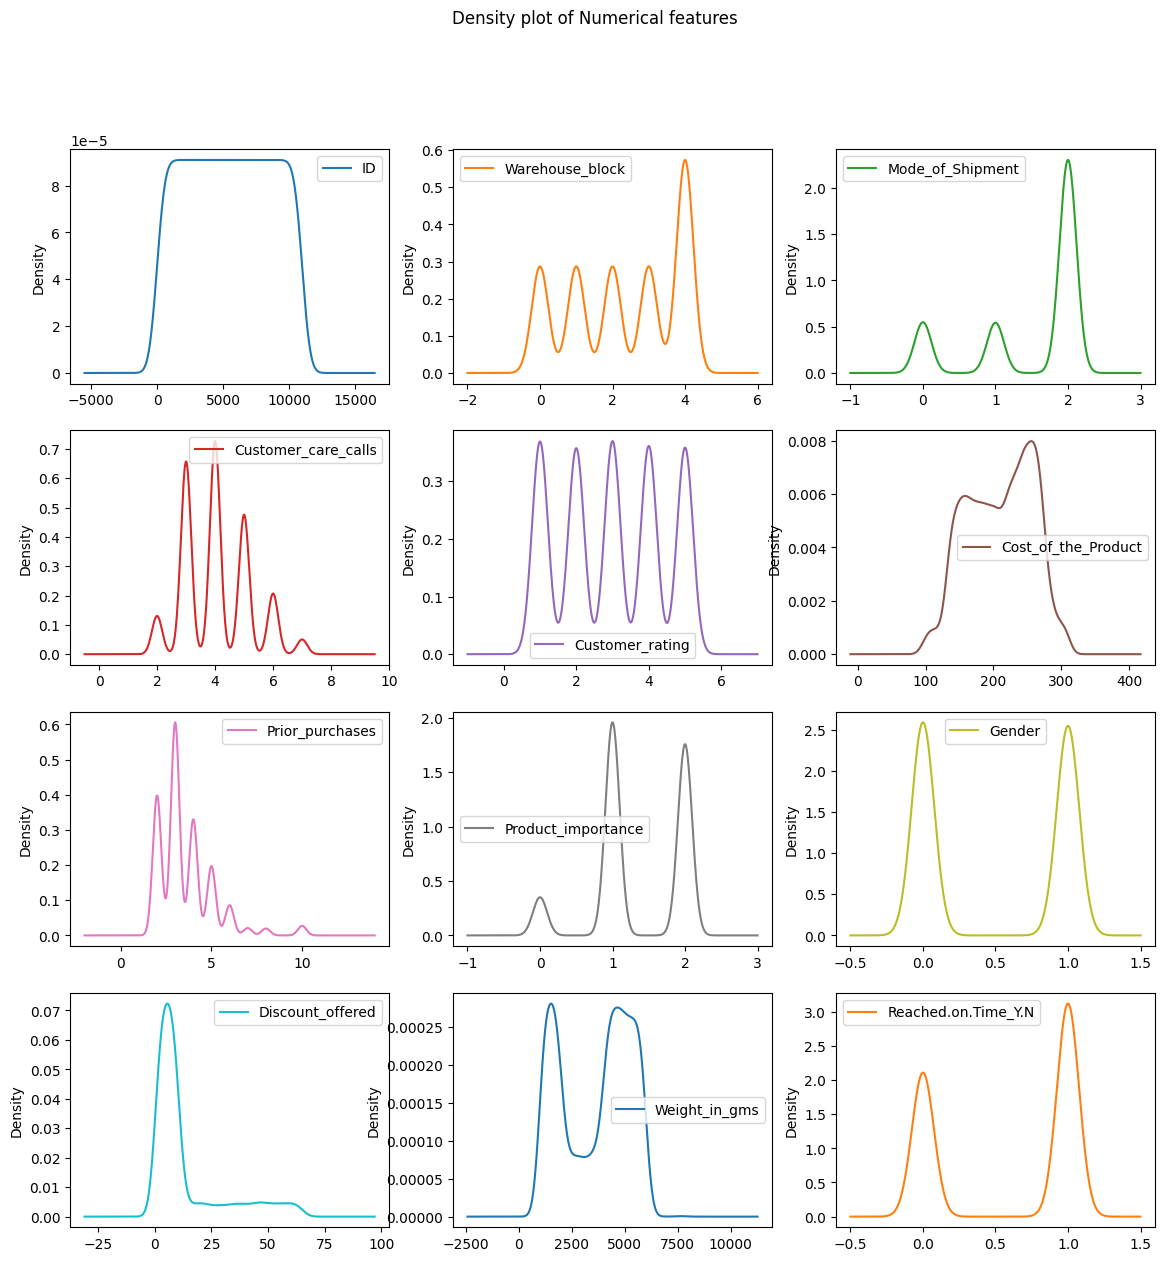

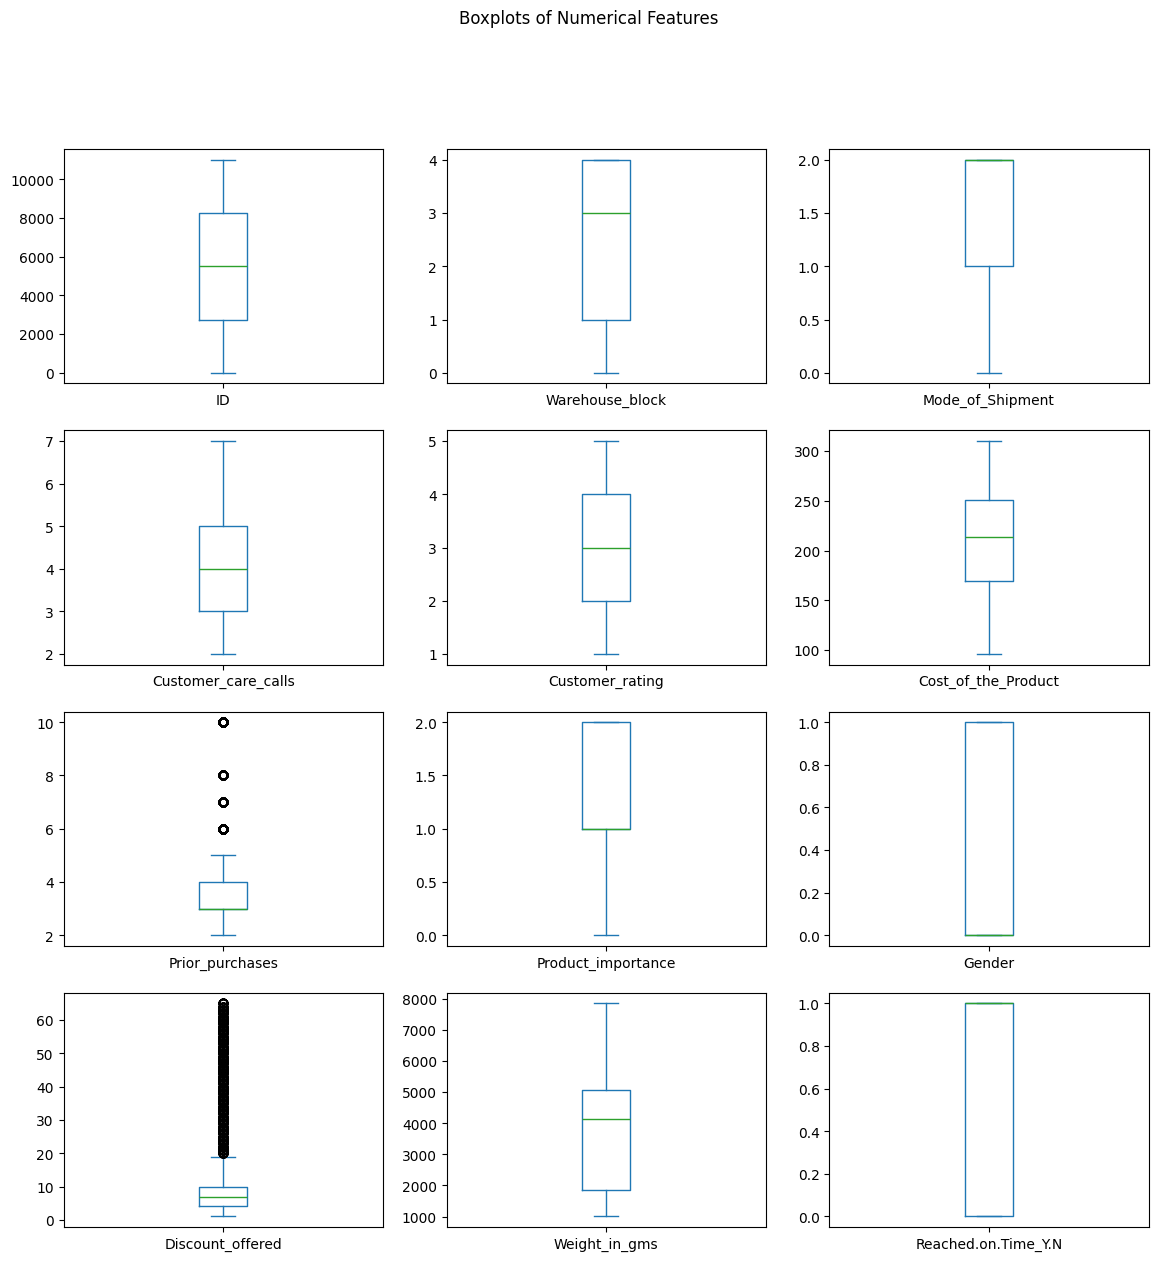

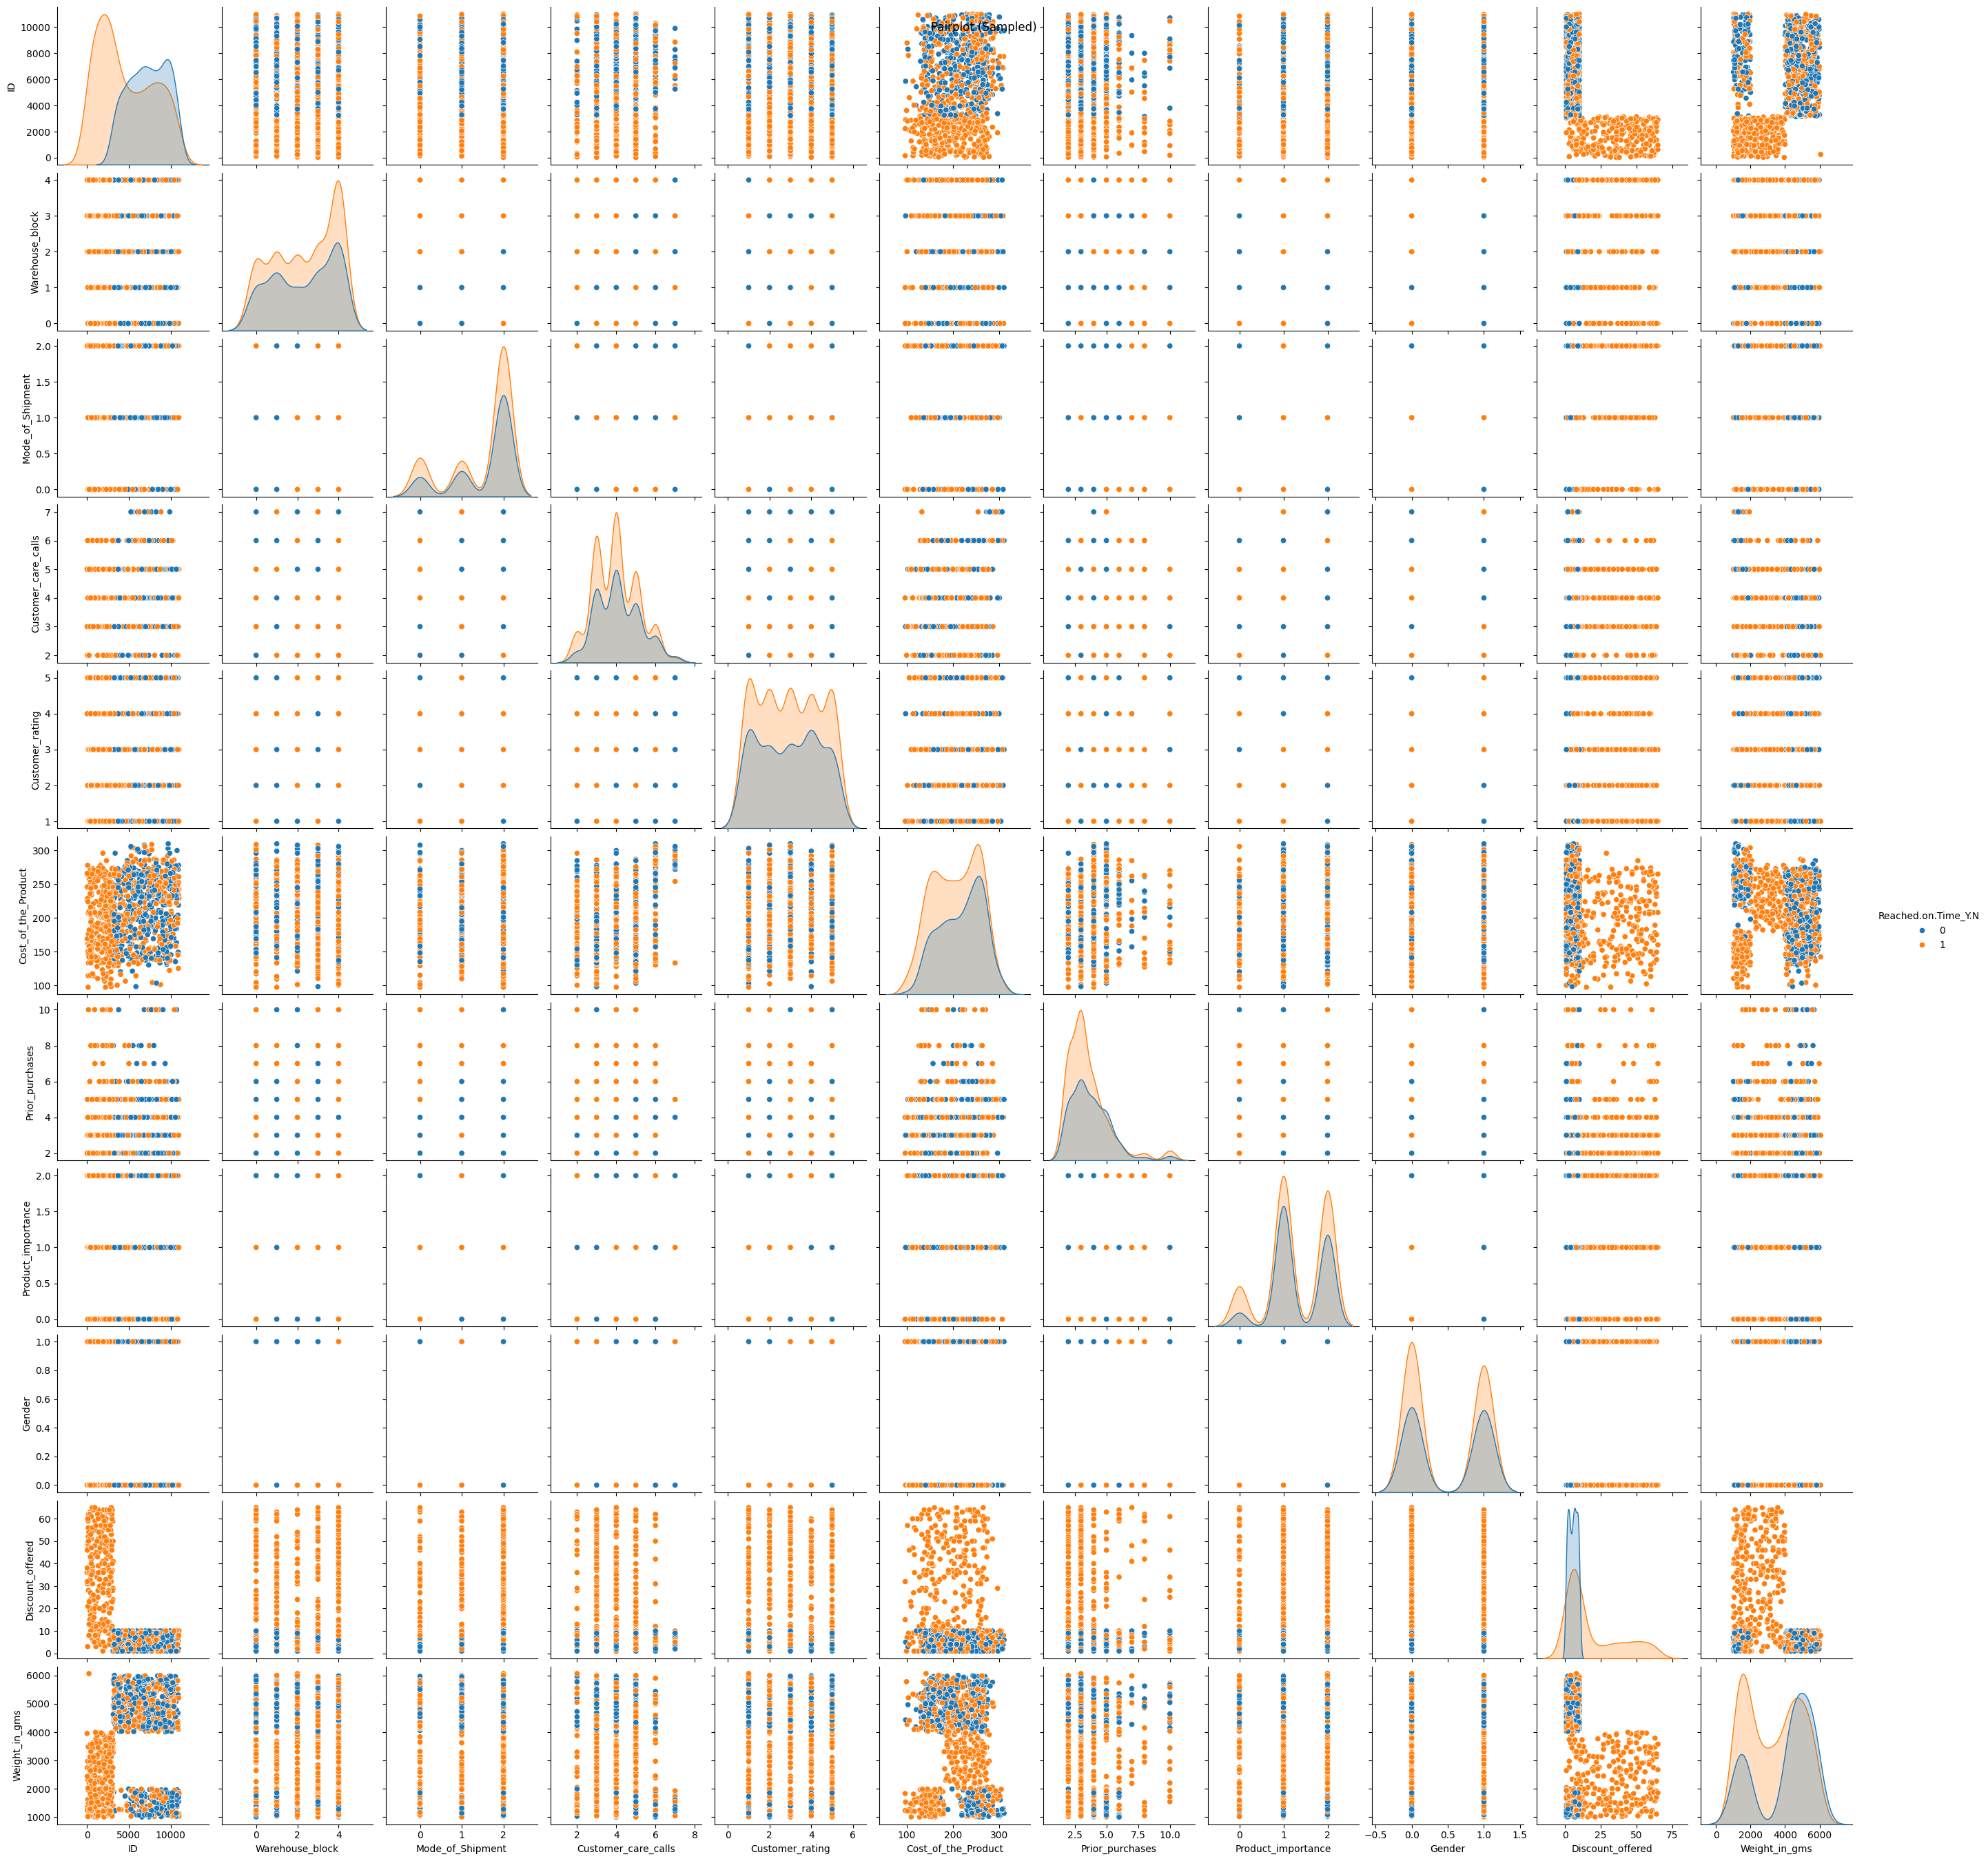


Preprocessing:
Null/Missing values:
 ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64
Categorical values:  ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']
Feature Scaling: Needed for distance-based models like KNN.
After Preprocessing:
    Customer_care_calls  Customer_rating  Cost_of_the_Product  Prior_purchases  \
0            -0.047711        -0.700755            -0.690722        -0.372735   
1            -0.047711         1.421578             0.120746        -1.029424   
2            -1.799887        -0.700755            -0.565881         0.283954   
3            -0.923799         0.006689            -0.711529         0.283954   
4            -1.799887        -0.700755            -0.545074        -

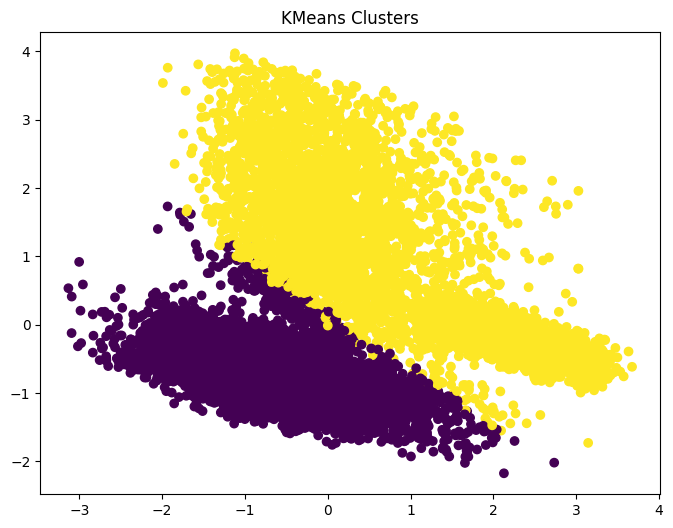

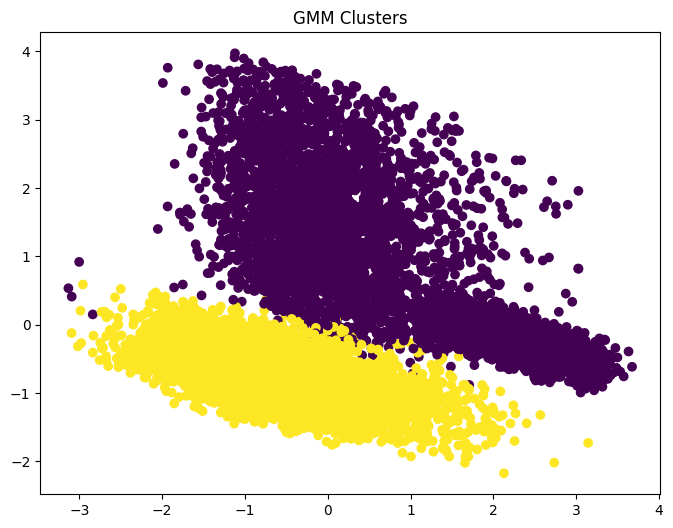

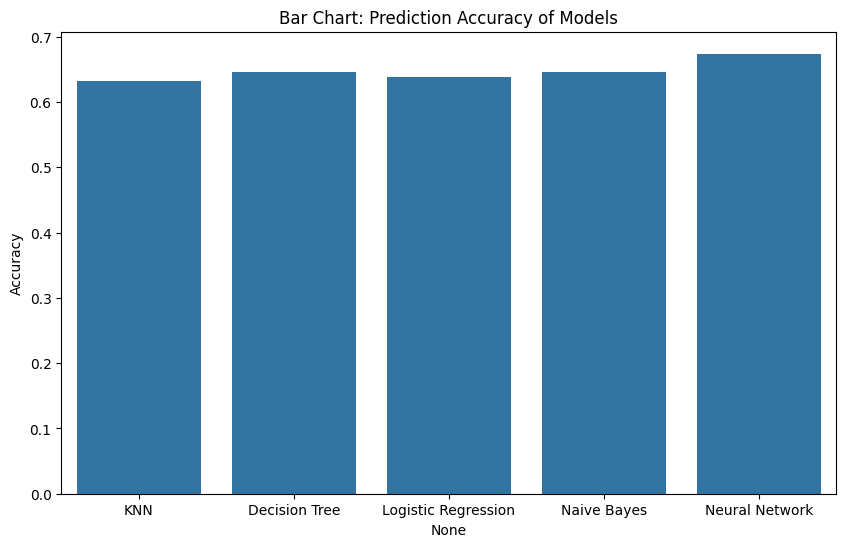

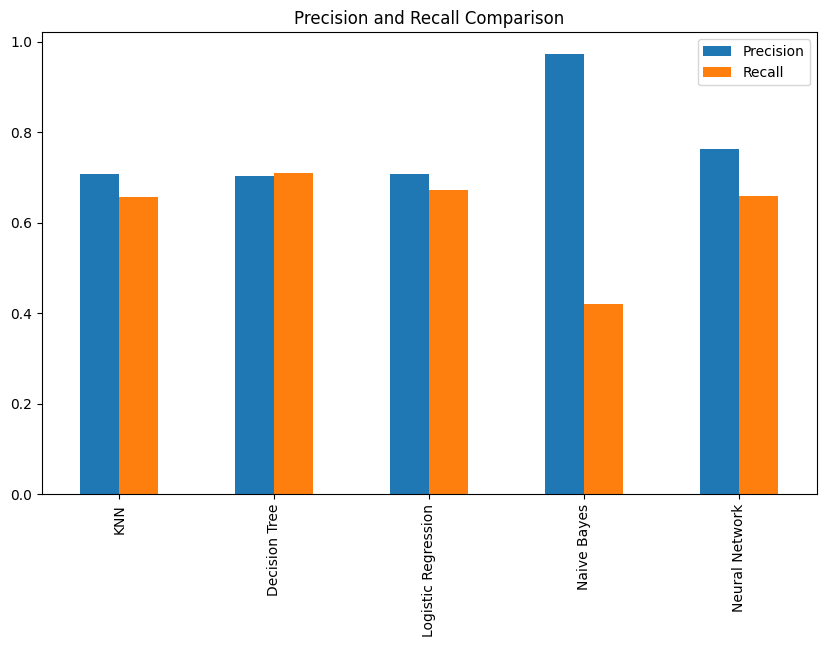

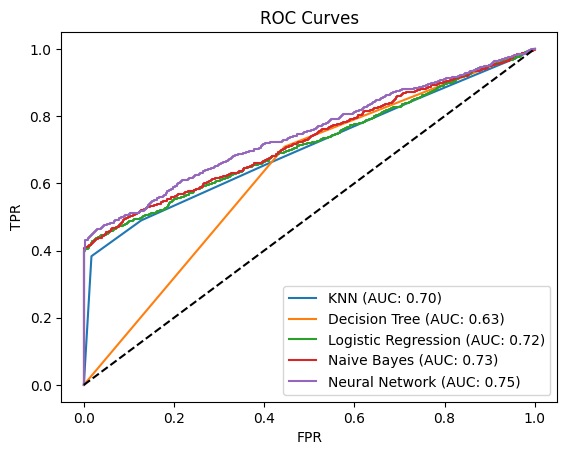


Project Complete.


In [1]:
# CSE422 Lab Project Implementation
# Dataset: E-commerce Shipping Dataset.csv
# This script implements the complete project tasks as per the report template.
# It includes EDA, preprocessing, splitting, model training (supervised and unsupervised),
# evaluation, and comparison.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, accuracy_score
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# 1. Introduction
# (Comments: This project aims to predict if e-commerce shipments reach on time based on features like warehouse, shipment mode, etc.
# Problem: Binary classification - on time (0) or not (1). Motivation: Improve logistics efficiency.)

# Load the dataset
data = pd.read_csv('/content/E-commerce Shipping Dataset.csv')

# 2. Dataset Description
print("\nDataset Description:")
print("How many features? ", data.shape[1] - 1)  # Excluding ID and target
print("Classification or regression problem? Classification (binary: on time or not)")
print("How many data points? ", data.shape[0])
print("Features types: Quantitative (e.g., Cost_of_the_Product, Weight_in_gms), Categorical (e.g., Warehouse_block, Gender)")

# Check for encoding needs
categorical_cols = ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']
print("Categorical features need encoding: Yes, for ML models.")

# Correlation (after encoding numerical parts)
# First, encode categoricals for correlation
le = LabelEncoder()
data_encoded = data.copy()
for col in categorical_cols:
    data_encoded[col] = le.fit_transform(data_encoded[col])

# Correlation heatmap (from EDA_CSE422_Lab.ipynb snippet)
numerical_data = data_encoded.select_dtypes(include=[np.number])
corr = numerical_data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()
print("After correlation: Discount_offered and Reached.on.Time_Y.N have moderate correlation. Weight_in_gms negative correlation with target.")

# Imbalanced Dataset
target = 'Reached.on.Time_Y.N'
class_counts = data[target].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Bar Chart of Classes (Imbalanced Check)")
plt.xlabel("Classes (0: On Time, 1: Late)")
plt.ylabel("Number of Instances")
plt.show()
print("Imbalanced? Yes, more late shipments (1) than on time (0).")

# Perform EDA (from EDA_CSE422_Lab.ipynb)
print("\nEDA:")
print(data.head())
print(data.info())
print(data.describe())

# Univariate analysis (histograms)
data.hist(figsize=(14, 14))
plt.suptitle("Histograms of Numerical Features")
plt.show()

# Density plots
numerical_data.plot(kind='density', figsize=(14, 14), subplots=True, layout=(4, 3), title="Density plot of Numerical features", sharex=False)
plt.show()

# Boxplots
numerical_data.plot(kind='box', figsize=(14, 14), subplots=True, layout=(4, 3))
plt.suptitle("Boxplots of Numerical Features")
plt.show()

# Pairplot (sample for speed)
sns.pairplot(data_encoded.sample(1000), hue=target)
plt.suptitle("Pairplot (Sampled)")
plt.show()

# 3. Dataset Pre-processing
print("\nPreprocessing:")

# Faults
print("Null/Missing values:\n", data.isnull().sum())  # Assuming no nulls from data
print("Categorical values: ", categorical_cols)
print("Feature Scaling: Needed for distance-based models like KNN.")

# Solutions
# Delete rows/columns: None needed
# Encoding (OneHot for categoricals)
data_preprocessed = pd.get_dummies(data, columns=categorical_cols, drop_first=True)

# Drop ID
data_preprocessed.drop('ID', axis=1, inplace=True)

# Scaling (StandardScaler from Machine_Learning_+_Preprocessing.ipynb)
scaler = StandardScaler()
numerical_cols = ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
data_preprocessed[numerical_cols] = scaler.fit_transform(data_preprocessed[numerical_cols])

print("After Preprocessing:\n", data_preprocessed.head())

# 4. Dataset Splitting
X = data_preprocessed.drop(target, axis=1)
y = data_preprocessed[target]

# Stratified split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train set: 80%, Test set: 20% (Stratified)")

# 5. Model Training & Testing (Supervised)
models = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Naive Bayes': GaussianNB(),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
}

results = {}
for name, model in models.items():
    # K-Fold CV (from K_Fold_Cross_Validation.ipynb)
    kf = StratifiedKFold(n_splits=5)
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='accuracy')
    print(f"{name} CV Accuracy: {cv_scores.mean():.2f}")

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else None

    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1, 'AUC': auc}

    print(f"{name} Test Accuracy: {acc:.2f}")
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))

# Treat as unsupervised (KMeans from CSE 422 Lab 5 part 1 and Model_Evaluation.ipynb)
# Drop target for unsupervised
X_unsup = X.copy()

# KMeans
kmeans = KMeans(n_clusters=2, random_state=10)  # Binary, so 2 clusters
kmeans.fit(X_unsup)
predictions = kmeans.labels_
print("KMeans Predictions:", predictions)

# Visualize clusters (PCA for 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_unsup)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=predictions, cmap='viridis')
plt.title("KMeans Clusters")
plt.show()

# GMM (from CSE 422 Lab 5 part 2)
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(X_unsup)
gmm_labels = gmm.predict(X_unsup)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='viridis')
plt.title("GMM Clusters")
plt.show()

# 6. Model Selection/Comparison Analysis
# Bar chart accuracy
acc_df = pd.DataFrame.from_dict(results, orient='index')['Accuracy']
plt.figure(figsize=(10, 6))
sns.barplot(x=acc_df.index, y=acc_df.values)
plt.title("Bar Chart: Prediction Accuracy of Models")
plt.ylabel("Accuracy")
plt.show()

# Precision, Recall comparison
prec_df = pd.DataFrame.from_dict(results, orient='index')[['Precision', 'Recall']]
prec_df.plot(kind='bar', figsize=(10, 6))
plt.title("Precision and Recall Comparison")
plt.show()

# AUC ROC (from Model_Evaluation.ipynb)
for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC: {roc_auc_score(y_test, y_prob):.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curves")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()

# 7. Conclusion
# (Comments: From results, Neural Network performs best with high accuracy. Imbalance affects recall for class 0.
# Challenges: Handling categoricals, imbalance. Suggestions: Use SMOTE for balance.)
print("\nProject Complete.")